## LIGHT GBM AND XGBoost


importing libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.model_selection import (train_test_split,
                                     cross_val_score,
                                     StratifiedKFold,
                                     GridSearchCV)
from sklearn.metrics import (accuracy_score,
                             precision_score,
                             recall_score,
                             f1_score,
                             classification_report,
                             confusion_matrix,
                             roc_auc_score,
                             ConfusionMatrixDisplay,
                             RocCurveDisplay,
                             roc_curve)

# Import LightGBM and XGBoost
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier


LOADING AND UNDERSTANDING DATASET

In [2]:
df= pd.read_csv("d:\\project\\13. XGBM & LGBM\\diabetes.csv")

In [3]:
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [4]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [6]:
print("Statistical Summary of the dataset")
df.describe()

Statistical Summary of the dataset


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [7]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (768, 9)


In [8]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [12]:
df['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

## Exploratory Data Analyis

EDA is performed to understand the distribution of the features and the target variable.

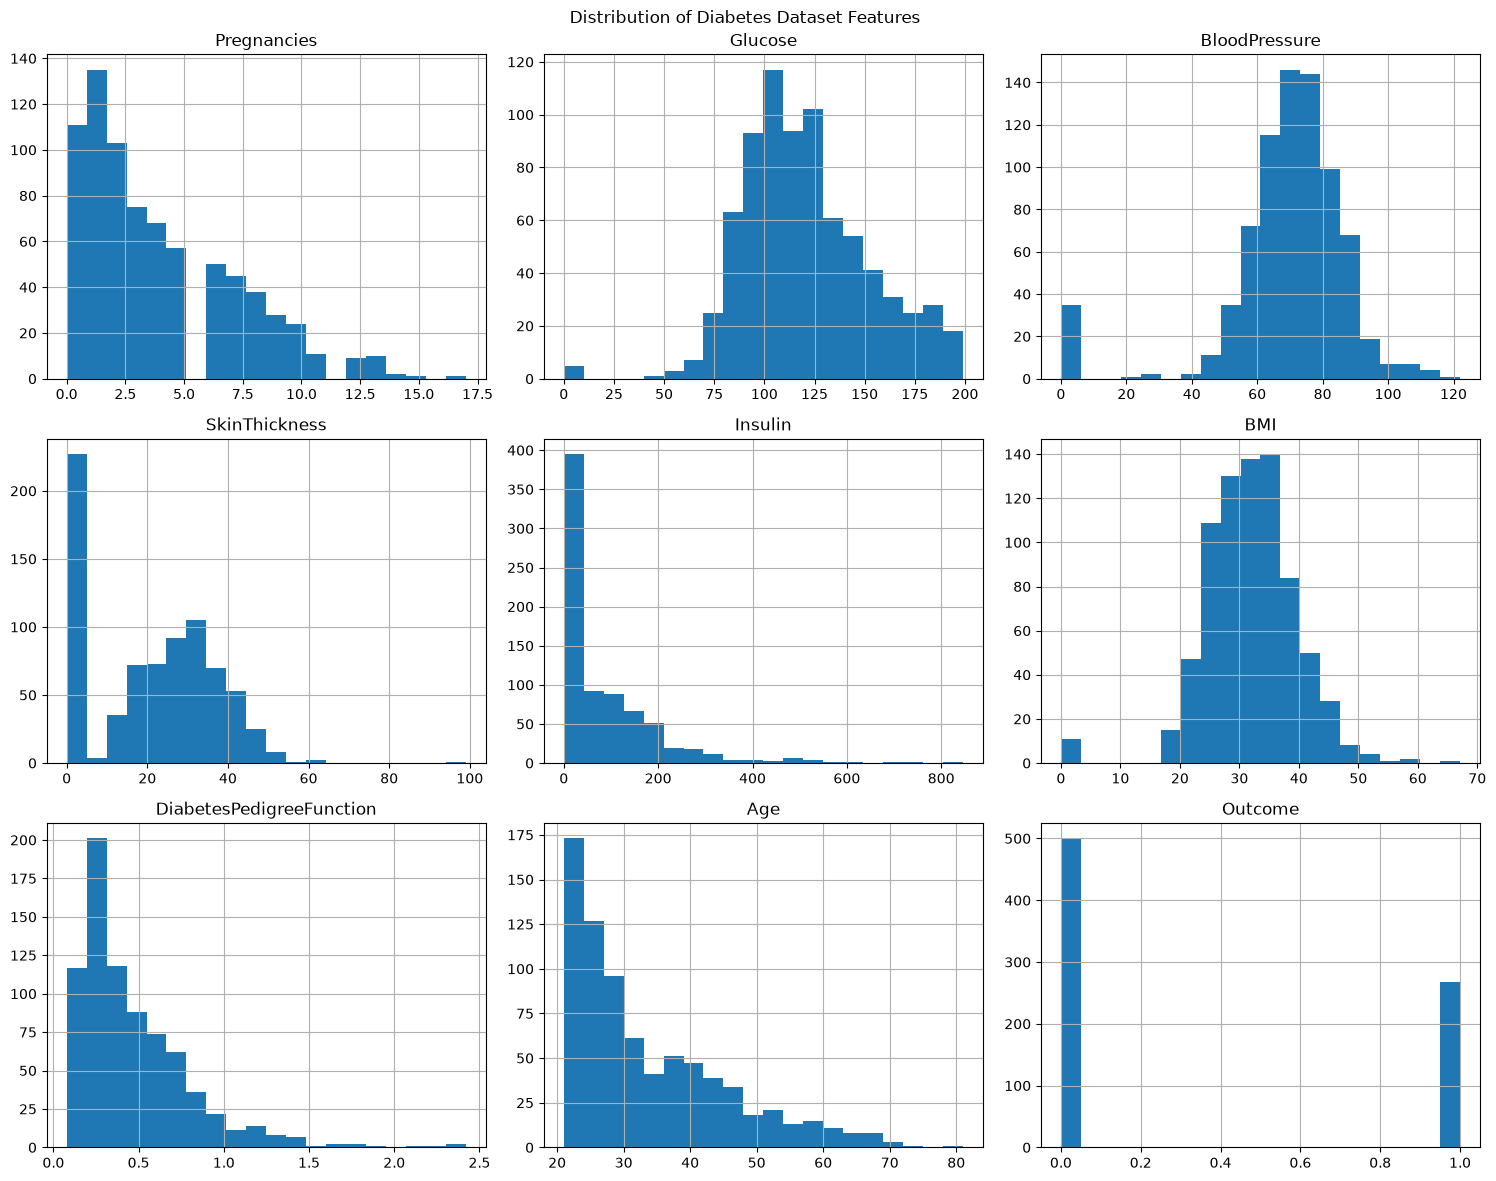

In [13]:
df.hist(figsize=(15, 12), bins=20)

plt.suptitle("Distribution of Diabetes Dataset Features")
plt.tight_layout()
plt.show()

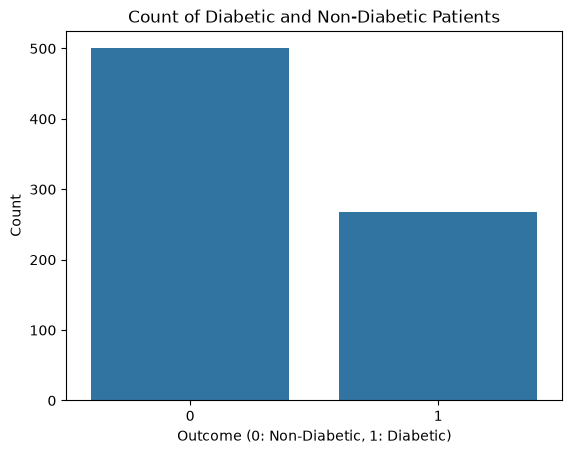

In [14]:
sns.countplot(x='Outcome', data=df)
plt.title("Count of Diabetic and Non-Diabetic Patients")
plt.xlabel("Outcome (0: Non-Diabetic, 1: Diabetic)")
plt.ylabel("Count")
plt.show()

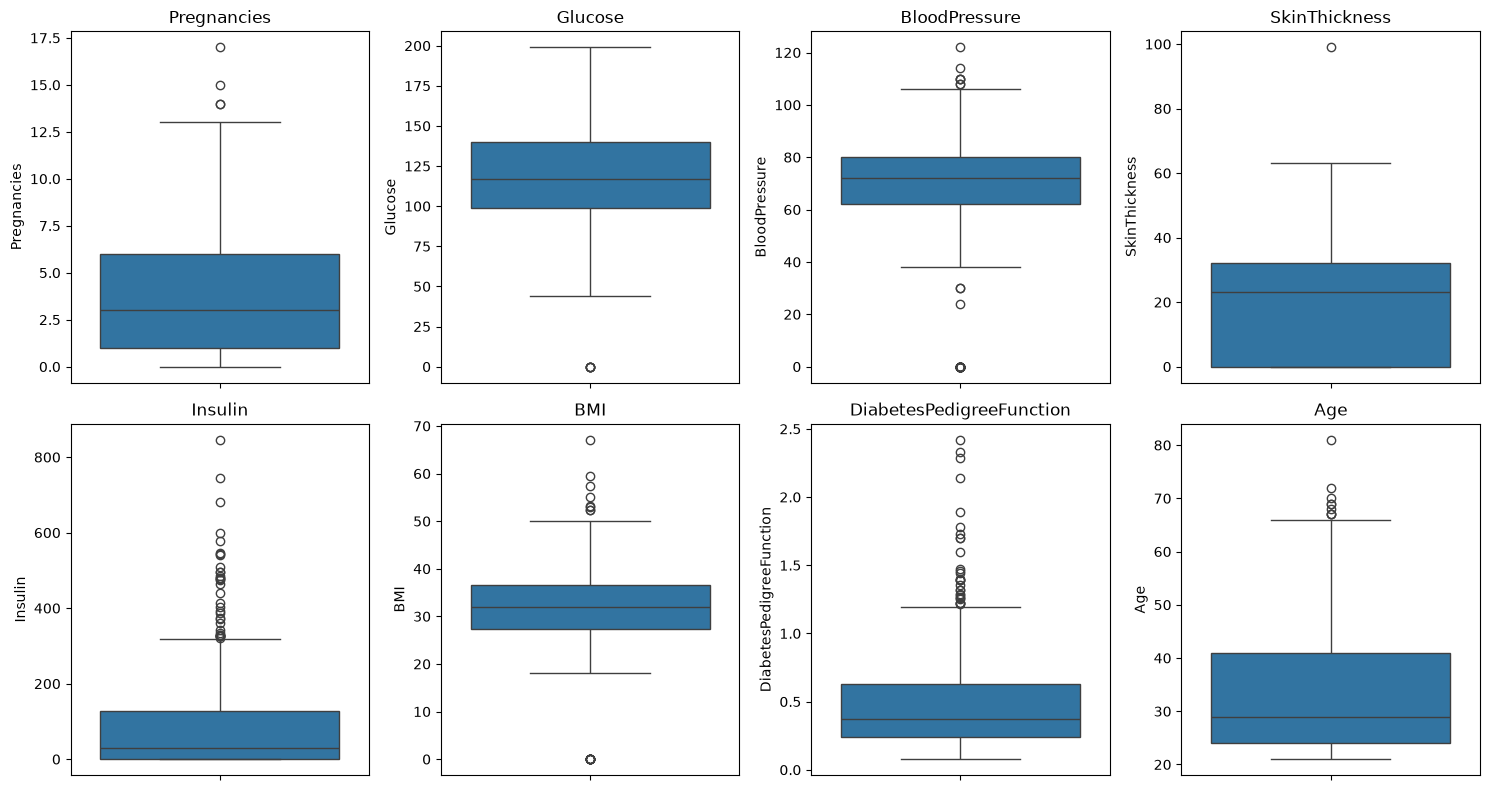

In [15]:
plt.figure(figsize=(15, 8))

for i, col in enumerate(df.drop(columns='Outcome').columns):
    plt.subplot(2, 4, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

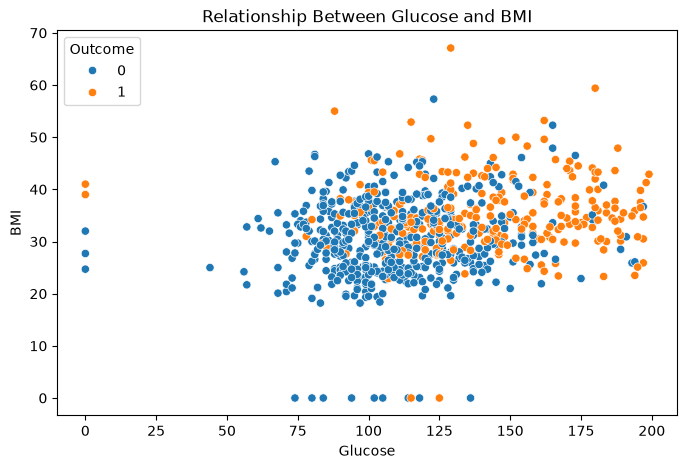

In [16]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x='Glucose',
    y='BMI',
    hue='Outcome',
    data=df
)

plt.title("Relationship Between Glucose and BMI")
plt.xlabel("Glucose")
plt.ylabel("BMI")

plt.show()

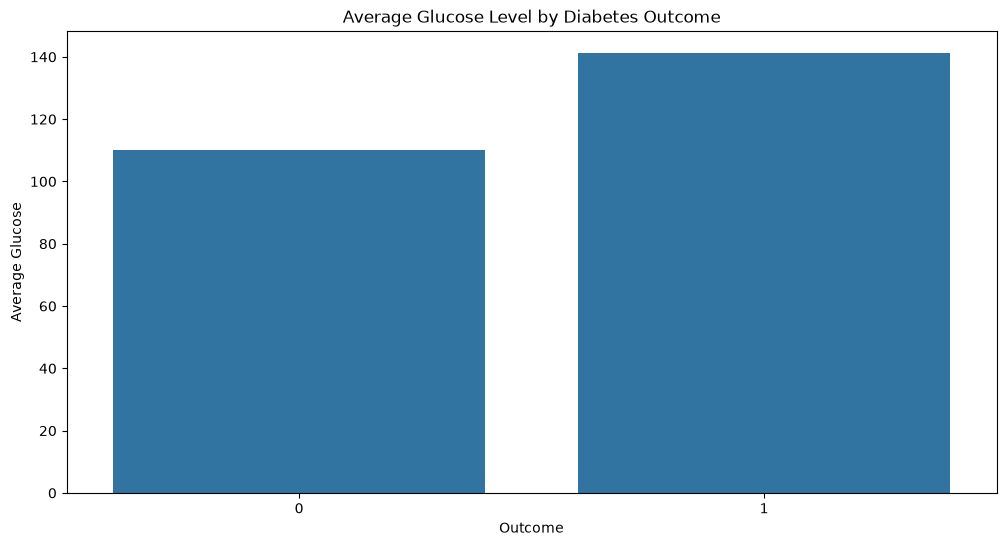

In [17]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x='Outcome',
    y='Glucose',
    data=df,
    errorbar=None
)

plt.title("Average Glucose Level by Diabetes Outcome")
plt.xlabel("Outcome")
plt.ylabel("Average Glucose")

plt.show()

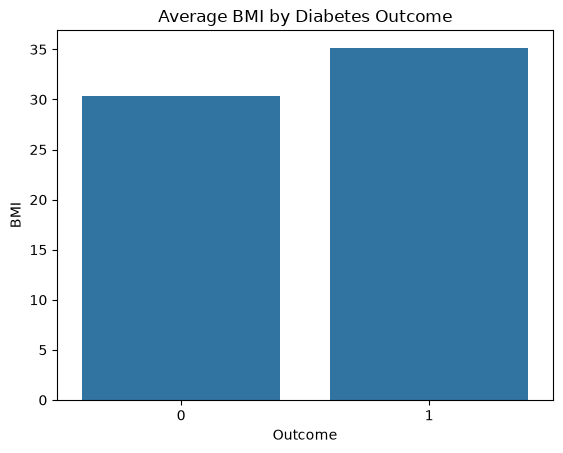

In [18]:
sns.barplot(x='Outcome', y='BMI', data=df, errorbar=None)

plt.title("Average BMI by Diabetes Outcome")
plt.show()

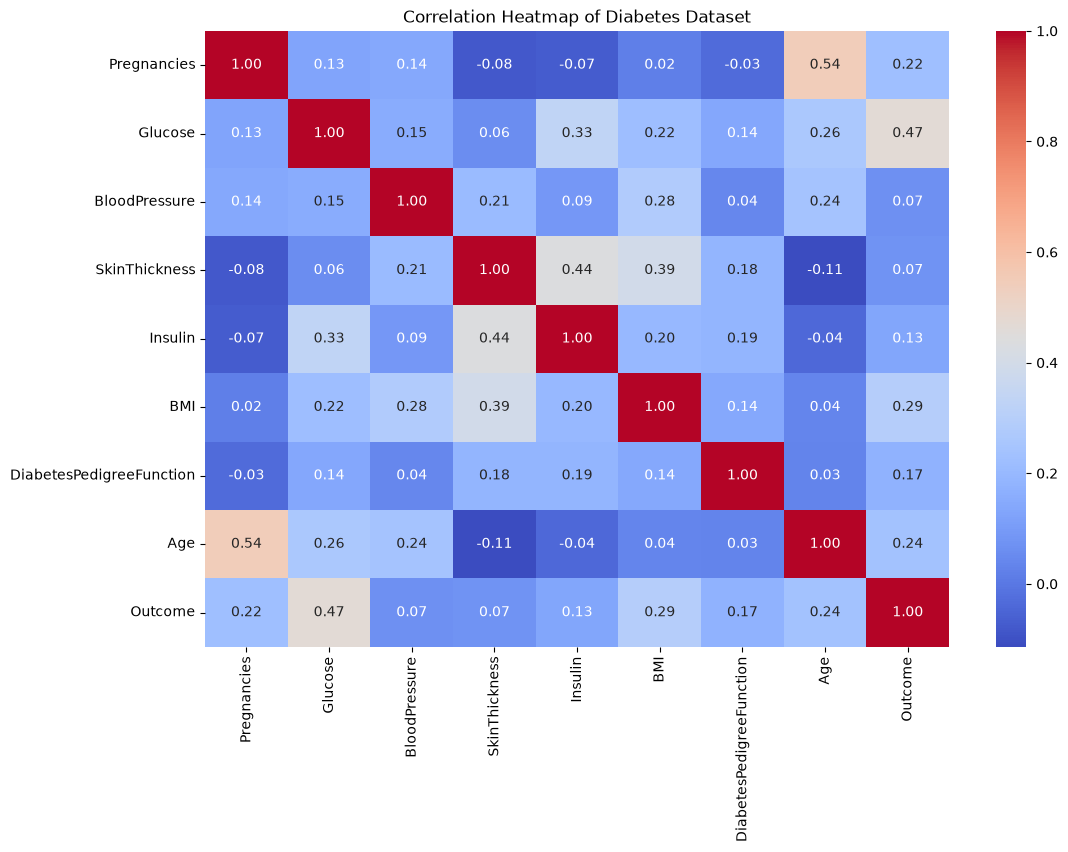

In [19]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap of Diabetes Dataset")
plt.show()

## DATA PREPROCESSING AND FEATURE SELECTION

In [20]:
X = df.drop('Outcome', axis=1)

y = df['Outcome']


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [22]:
imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X.columns,
    index=X_test.index
)

In [23]:
X_train.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64

BUILDING THE LIGHTGBM MODEL

In [24]:
lgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=-1,
    random_state=42,
    verbosity=-1
)

In [25]:
lgbm_model.fit(X_train, y_train)

,learning_rate,0.05
,random_state,42
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


In [26]:
lgbm_pred = lgbm_model.predict(X_test)

In [27]:
lgbm_prob = lgbm_model.predict_proba(X_test)[:, 1]

In [ ]:
print("LightGBM Accuracy:", accuracy_score(y_test, lgbm_pred))
print("LightGBM Precision:", precision_score(y_test, lgbm_pred, zero_division=0))
print("LightGBM Recall:", recall_score(y_test, lgbm_pred, zero_division=0))
print("LightGBM F1 Score:", f1_score(y_test, lgbm_pred, zero_division=0))
print("LightGBM ROC-AUC:", roc_auc_score(y_test, lgbm_prob))

LightGBM Accuracy: 0.7727272727272727
LightGBM Precision: 0.7111111111111111
LightGBM Recall: 0.5925925925925926
LightGBM F1 Score: 0.6464646464646465
LightGBM ROC-AUC: 0.8303703703703704


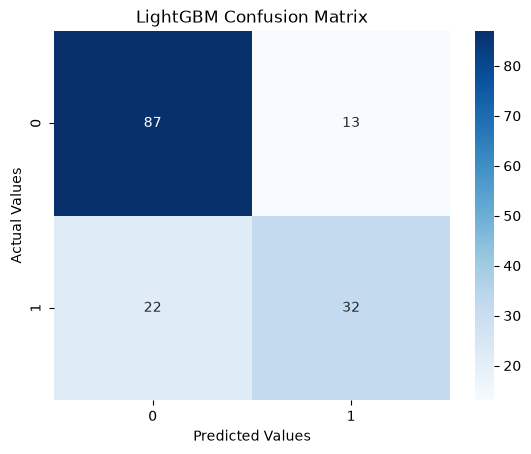

In [29]:
cm_lgbm = confusion_matrix(y_test, lgbm_pred)

sns.heatmap(
    cm_lgbm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("LightGBM Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

BUILDING THE XGBOOST MODEL

In [30]:
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    eval_metric='logloss'
)

In [31]:
xgb_model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [32]:
xgb_pred = xgb_model.predict(X_test)

In [33]:
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

In [ ]:
print("XGBoost Accuracy:", accuracy_score(y_test, xgb_pred))
print("XGBoost Precision:", precision_score(y_test, xgb_pred, zero_division=0))
print("XGBoost Recall:", recall_score(y_test, xgb_pred, zero_division=0))
print("XGBoost F1 Score:", f1_score(y_test, xgb_pred, zero_division=0))
print("XGBoost ROC-AUC:", roc_auc_score(y_test, xgb_prob))

XGBoost Accuracy: 0.7467532467532467
XGBoost Precision: 0.6530612244897959
XGBoost Recall: 0.5925925925925926
XGBoost F1 Score: 0.6213592233009708
XGBoost ROC-AUC: 0.8246296296296296


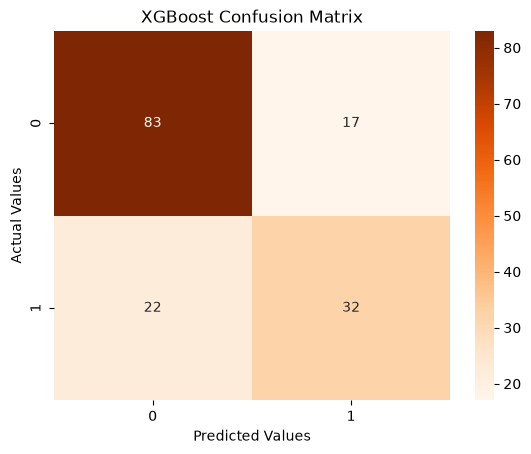

In [35]:
cm_xgb = confusion_matrix(y_test, xgb_pred)

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt='d',
    cmap='Oranges'
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

CROSS VALIDATION

In [36]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lgbm_cv = cross_val_score(
    lgbm_model,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy'
)

print("LightGBM CV Scores:", lgbm_cv)


print("LightGBM Average CV Accuracy:", lgbm_cv.mean())

LightGBM CV Scores: [0.78861789 0.72357724 0.7804878  0.72357724 0.76229508]
LightGBM Average CV Accuracy: 0.7557110489137678


In [37]:
xgb_cv = cross_val_score(
    xgb_model,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy'
)

print("XGBoost CV Scores:", xgb_cv)

print("XGBoost Average CV Accuracy:", xgb_cv.mean())

XGBoost CV Scores: [0.78861789 0.78861789 0.78861789 0.73170732 0.74590164]
XGBoost Average CV Accuracy: 0.7686925229908037


HYPERPARAMETER TUNING - LIGHTGBM

In [38]:
lgbm_params = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [-1, 5, 10],
    'num_leaves': [15, 31]
}

In [39]:
lgbm_grid = GridSearchCV(
    estimator=LGBMClassifier(
        random_state=42,
        verbosity=-1
    ),
    param_grid=lgbm_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

lgbm_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LGBMClassifie... verbosity=-1)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.01, 0.05, ...], 'max_depth': [-1, 5, ...], 'n_estimators': [50, 100, ...], 'num_leaves': [15, 31]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verb

In [40]:
print("Best LightGBM Parameters:", lgbm_grid.best_params_)

print("Best LightGBM CV Score:", lgbm_grid.best_score_)

Best LightGBM Parameters: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 50, 'num_leaves': 31}
Best LightGBM CV Score: 0.7704251632680262


In [41]:
best_lgbm = lgbm_grid.best_estimator_

HYPERPARAMETER TUNING - XGBOOST

In [42]:
xgb_params = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

In [43]:
xgb_grid = GridSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    ),
    param_grid=xgb_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

xgb_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added

In [44]:
print("Best XGBoost Parameters:", xgb_grid.best_params_)

print("Best XGBoost CV Score:", xgb_grid.best_score_)

Best XGBoost Parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 150, 'subsample': 0.8}
Best XGBoost CV Score: 0.7687858190057311


In [45]:
best_xgb = xgb_grid.best_estimator_

EVALUATION

In [46]:
best_lgbm_pred = best_lgbm.predict(X_test)

best_lgbm_prob = best_lgbm.predict_proba(X_test)[:, 1]

In [ ]:
print("Accuracy:", accuracy_score(y_test, best_lgbm_pred))
print("Precision:", precision_score(y_test, best_lgbm_pred, zero_division=0))
print("Recall:", recall_score(y_test, best_lgbm_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, best_lgbm_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, best_lgbm_prob))

Accuracy: 0.7922077922077922
Precision: 0.7391304347826086
Recall: 0.6296296296296297
F1 Score: 0.68
ROC-AUC: 0.8342592592592593


In [48]:
best_xgb_pred = best_xgb.predict(X_test)

best_xgb_prob = best_xgb.predict_proba(X_test)[:, 1]

In [ ]:
print("Accuracy:", accuracy_score(y_test, best_xgb_pred))
print("Precision:", precision_score(y_test, best_xgb_pred, zero_division=0))
print("Recall:", recall_score(y_test, best_xgb_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, best_xgb_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, best_xgb_prob))

Accuracy: 0.7532467532467533
Precision: 0.6666666666666666
Recall: 0.5925925925925926
F1 Score: 0.6274509803921569
ROC-AUC: 0.832962962962963


COMPARATIVE PERFORMANCE ANALYSIS

In [50]:
comparison = pd.DataFrame({
    'Model': ['LightGBM', 'XGBoost'],

    'Accuracy': [
        accuracy_score(y_test, best_lgbm_pred),
        accuracy_score(y_test, best_xgb_pred)
    ],

    'Precision': [
        precision_score(y_test, best_lgbm_pred, zero_division=0),
        precision_score(y_test, best_xgb_pred, zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, best_lgbm_pred, zero_division=0),
        recall_score(y_test, best_xgb_pred, zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, best_lgbm_pred, zero_division=0),
        f1_score(y_test, best_xgb_pred, zero_division=0)
    ],

    'ROC-AUC': [
        roc_auc_score(y_test, best_lgbm_prob),
        roc_auc_score(y_test, best_xgb_prob)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,LightGBM,0.792208,0.739130,0.629630,0.680000,0.834259
1,XGBoost,0.753247,0.666667,0.592593,0.627451,0.832963


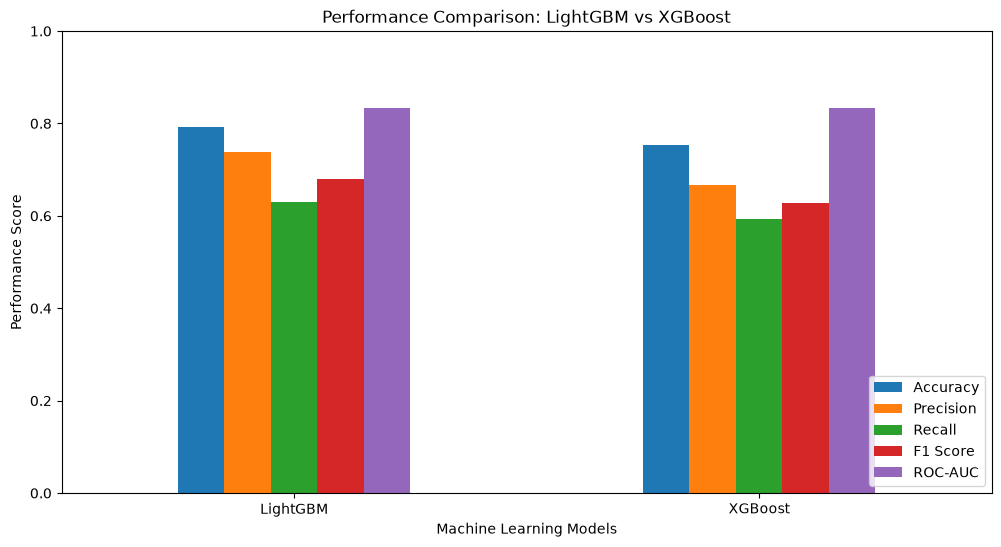

In [51]:
comparison_plot = comparison.set_index('Model')

comparison_plot.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Performance Comparison: LightGBM vs XGBoost")
plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='lower right')

plt.show()

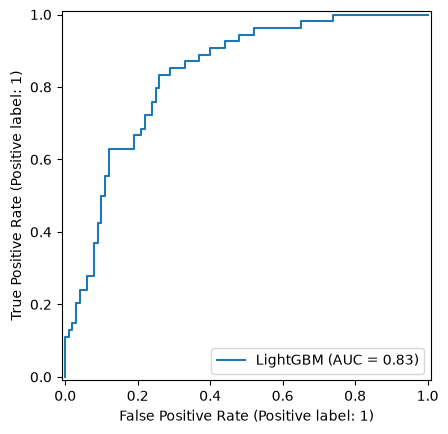

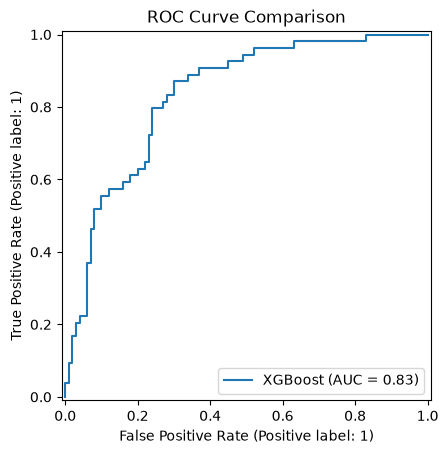

In [52]:
RocCurveDisplay.from_predictions(
    y_test,
    best_lgbm_prob,
    name='LightGBM'
)

RocCurveDisplay.from_predictions(
    y_test,
    best_xgb_prob,
    name='XGBoost'
)

plt.title("ROC Curve Comparison")
plt.show()

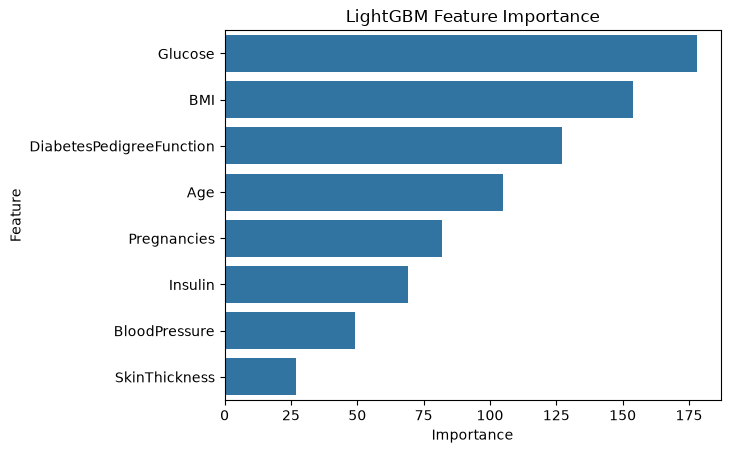

In [53]:
lgbm_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_lgbm.feature_importances_
})

lgbm_importance = lgbm_importance.sort_values(
    by='Importance',
    ascending=False
)

sns.barplot(
    x='Importance',
    y='Feature',
    data=lgbm_importance
)

plt.title("LightGBM Feature Importance")
plt.show()

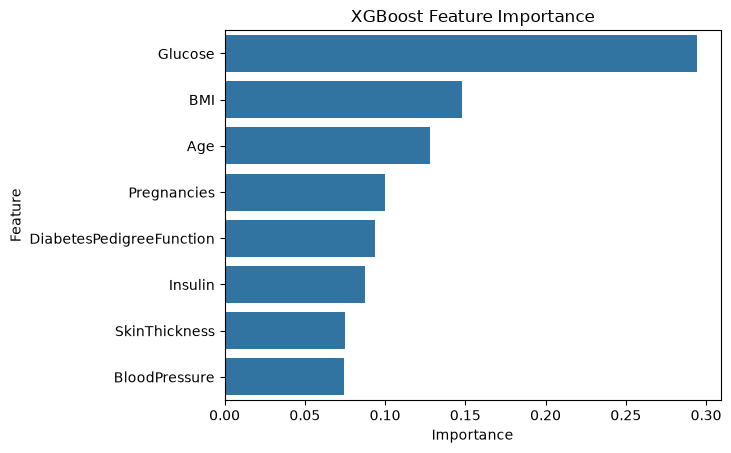

In [54]:
xgb_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_xgb.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by='Importance',
    ascending=False
)

sns.barplot(
    x='Importance',
    y='Feature',
    data=xgb_importance
)

plt.title("XGBoost Feature Importance")
plt.show()

## OBJECTIVE & CONCLUSION

The objective of this assingment was to build and compare LightGBM and XGBoost classification models of the Diabetes dataset.